In [1]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.1 kB]
Get:9 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:11 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,066 kB]
Hit:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:13 http://archive.ubuntu.com/ubuntu noble-

In [2]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Writing main.cpp


In [3]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [4]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Writing setup.sh


In [5]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


Renkli BMP


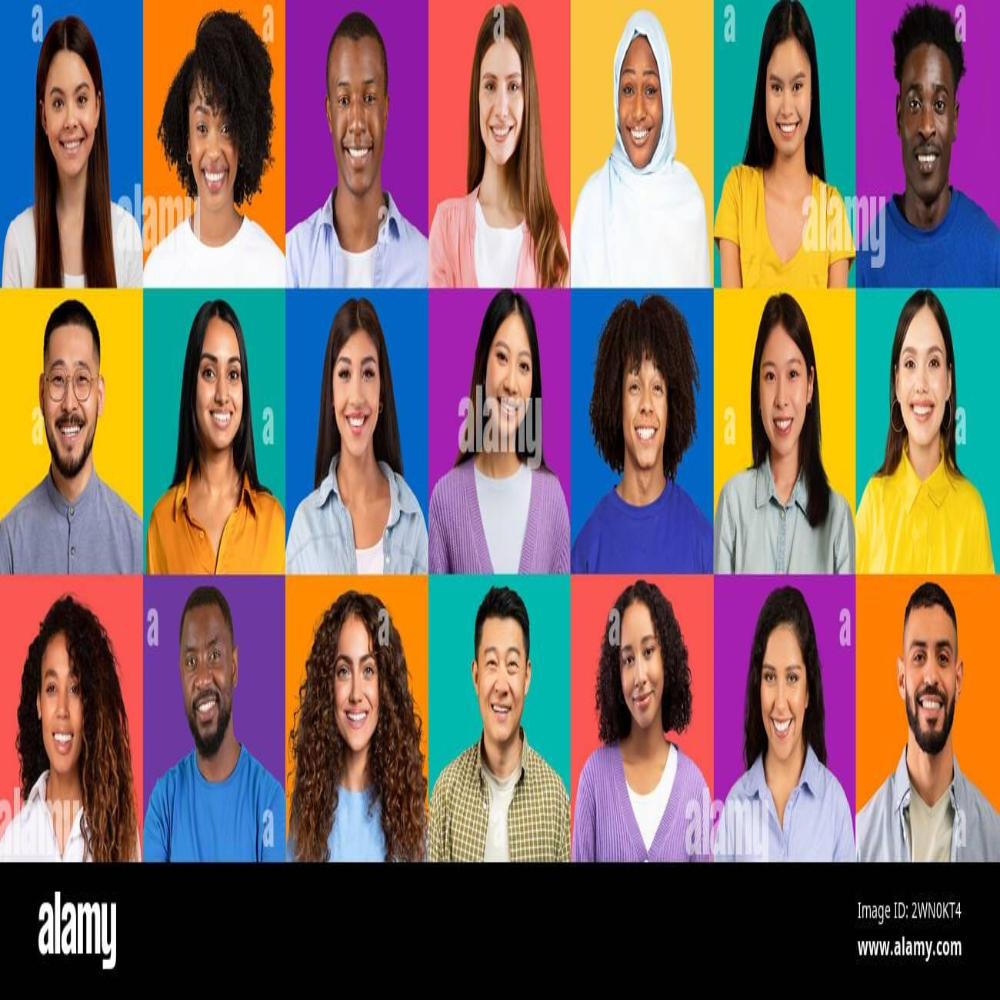

Gri BMP


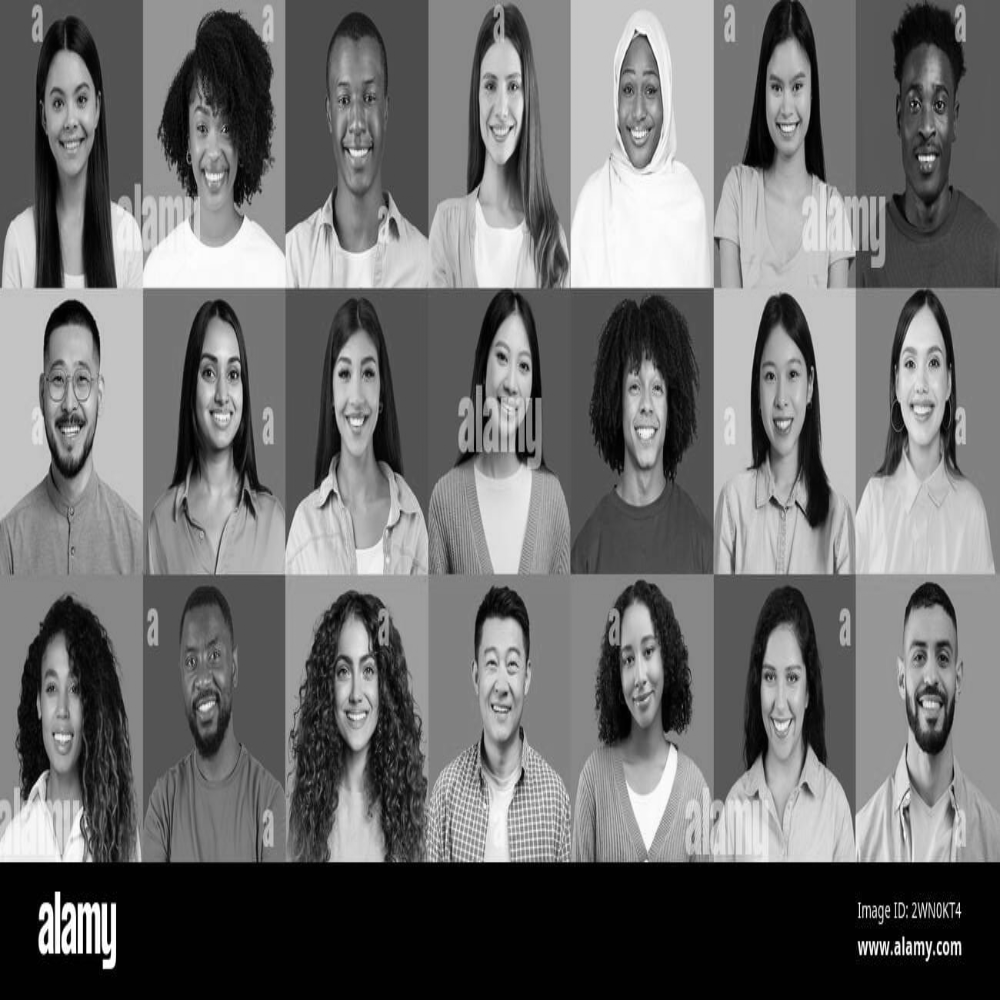

Renkli BMP | 1000x1000 | 3 kanal | 3000054 bayt
Gri BMP    | 1000x1000 | 1 kanal | 1001078 bayt
Boyut farkı: 1998976 bayt
Gri BMP %66.63 daha küçük.


In [7]:
import cv2
import os
from google.colab.patches import cv2_imshow


resim = cv2.imread("resim9.jpeg", cv2.IMREAD_COLOR)

if resim is None:
    raise FileNotFoundError("resim9.jpeg okunamadı. Dosyayı Colab'a yükle.")

resim = cv2.resize(resim, (1000, 1000))
cv2.imwrite("resim9_renkli.bmp", resim)


renkli = cv2.imread("resim9_renkli.bmp", cv2.IMREAD_COLOR)
print("Renkli BMP")
cv2_imshow(renkli)

gri = cv2.cvtColor(renkli, cv2.COLOR_BGR2GRAY)
cv2.imwrite("resim9_gri.bmp", gri)
print("Gri BMP")
cv2_imshow(gri)


renkli_boyut = os.path.getsize("resim9_renkli.bmp")
gri_boyut = os.path.getsize("resim9_gri.bmp")

print(f"Renkli BMP | 1000x1000 | 3 kanal | {renkli_boyut} bayt")
print(f"Gri BMP    | 1000x1000 | 1 kanal | {gri_boyut} bayt")
print(f"Boyut farkı: {renkli_boyut - gri_boyut} bayt")
print(f"Gri BMP %{100 * (1 - gri_boyut / renkli_boyut):.2f} daha küçük.")